## Notebook to just see the distribution of mood lables and split data before EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_sample = pd.read_csv("data/daily_fitbit_sema_df_unprocessed.csv")

### Data type of various features , missingness and distribution of various moods

In [3]:


mood_list = [
    "ALERT", "HAPPY", "NEUTRAL", "RESTED/RELAXED",
    "SAD", "TENSE/ANXIOUS", "TIRED"
]

# 1. Overall structure
print("SHAPE")
print(df_sample.shape)

print("\nUNIQUE PARTICIPANTS")
print(df_sample["id"].nunique())

print("\nDATE RANGE")
print(df_sample["date"].min(), "to", df_sample["date"].max())

# 2. Data types
print("\nDATA TYPES")
print(df_sample.dtypes.to_string())

# 3. Missingness
missing = pd.DataFrame({
    "missing_count": df_sample.isna().sum(),
    "missing_percent": 100 * df_sample.isna().mean()
}).sort_values("missing_percent", ascending=False)

print("\nMISSING VALUES")
print(missing.to_string())

# 4. Participant-date uniqueness
print("\nDUPLICATE PARTICIPANT-DATE ROWS")
print(df_sample.duplicated(["id", "date"]).sum())

# 5. Mood label distributions
print("\nMOOD LABEL VALUE COUNTS")
for mood in mood_list:
    print(f"\n{mood}")
    print(df_sample[mood].value_counts(dropna=False))

# 6. How many positive mood labels per row?
valid_moods = df_sample[mood_list].notna().all(axis=1)

positive_count = (
    df_sample.loc[valid_moods, mood_list]
    .eq(1)
    .sum(axis=1)
)

print("\nROWS WITH ALL SEVEN MOOD LABELS OBSERVED")
print(valid_moods.sum())

print("\nNUMBER OF POSITIVE MOODS PER COMPLETE ROW")
print(positive_count.value_counts().sort_index())


SHAPE
(7410, 63)

UNIQUE PARTICIPANTS
71

DATE RANGE
2021-04-08 to 2022-01-22

DATA TYPES
Unnamed: 0                            int64
id                                      str
date                                    str
nightly_temperature                 float64
nremhr                              float64
rmssd                               float64
spo2                                float64
full_sleep_breathing_rate           float64
stress_score                        float64
sleep_points_percentage             float64
exertion_points_percentage          float64
responsiveness_points_percentage    float64
daily_temperature_variation         float64
badgeType                               str
calories                            float64
filteredDemographicVO2Max           float64
distance                            float64
activityType                            str
bpm                                 float64
lightly_active_minutes              float64
moderately_active_minutes     

## Check to see whether all moods are present simultaneously in a row

In [4]:
# Rows where at least one mood value is recorded
any_mood = df_sample[mood_list].notna().any(axis=1)

# Rows where all mood values are recorded
all_mood = df_sample[mood_list].notna().all(axis=1)

print("Rows with any mood recorded:", any_mood.sum())
print("Rows with all moods recorded:", all_mood.sum())

Rows with any mood recorded: 2290
Rows with all moods recorded: 2290


This shows moods are present simultaneously and absent simultaneously in a row

## Participant Label Coverage , Daily coverage, Missingness for labeled participants

In [5]:

audit = df_sample.copy()
audit["date"] = pd.to_datetime(audit["date"], errors="coerce")

mood_list = [
    "ALERT", "HAPPY", "NEUTRAL", "RESTED/RELAXED",
    "SAD", "TENSE/ANXIOUS", "TIRED"
]

# 1.  labeled days per participant?
audit["has_mood_labels"] = audit[mood_list].notna().all(axis=1)

participant_coverage = (
    audit.groupby("id")
    .agg(
        total_rows=("date", "size"),
        labeled_rows=("has_mood_labels", "sum"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
)

participant_coverage["labeled_percent"] = (
    100 * participant_coverage["labeled_rows"]
    / participant_coverage["total_rows"]
)

print("PARTICIPANT LABEL COVERAGE")
print(participant_coverage.describe().round(2))

print("\nParticipants with no labeled rows:")
print((participant_coverage["labeled_rows"] == 0).sum())

print("\nParticipants with fewer than 10 labeled rows:")
print((participant_coverage["labeled_rows"] < 10).sum())

# 2. How are mood reports distributed over time?
daily_coverage = (
    audit.groupby("date")
    .agg(
        total_rows=("id", "size"),
        labeled_rows=("has_mood_labels", "sum"),
        participants=("id", "nunique")
    )
    .sort_index()
)

print("\nDAILY COVERAGE SUMMARY")
print(daily_coverage.describe().round(2))


'''
# 3. Check whether all mood columns are missing together
mood_missing_patterns = (
    audit[mood_list].isna()
    .value_counts()
    .rename("row_count")
)

print("\nMOOD MISSINGNESS PATTERNS")
print(mood_missing_patterns)
'''
# 4. Inspect feature coverage among rows with recorded moods
feature_missing = (
    audit.loc[audit["has_mood_labels"]]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("\nMISSINGNESS AMONG LABELED ROWS (%)")
print(feature_missing.round(1).to_string())


PARTICIPANT LABEL COVERAGE
       total_rows  labeled_rows                  first_date  \
count       71.00         71.00                          71   
mean       104.37         32.25  2021-07-17 21:17:44.788732   
min         64.00          0.00         2021-04-08 00:00:00   
25%         73.50          6.00         2021-05-24 00:00:00   
50%         88.00         32.00         2021-05-24 00:00:00   
75%        114.00         58.00         2021-10-14 12:00:00   
max        244.00         84.00         2021-11-16 00:00:00   
std         45.04         25.42                         NaN   

                        last_date  labeled_percent  
count                          71            71.00  
mean   2021-11-06 04:23:39.718309            36.37  
min           2021-07-26 00:00:00             0.00  
25%           2021-08-16 12:00:00             7.10  
50%           2021-10-14 00:00:00            27.78  
75%           2022-01-22 00:00:00            68.12  
max           2022-01-22 00:00:00 

## Plots of labels per participant , Moods reported over time, Frequency of positive mood labels

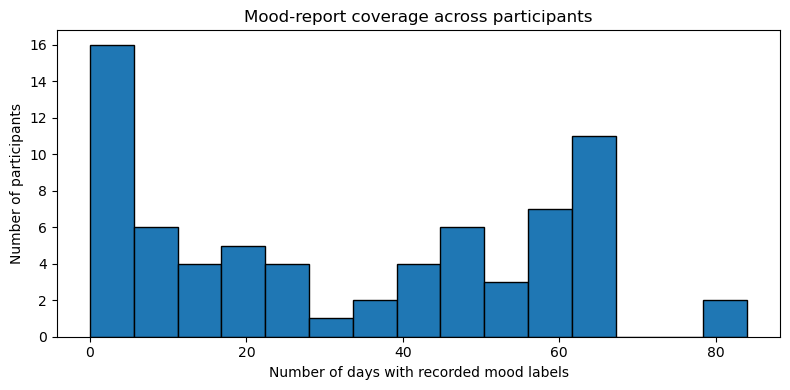

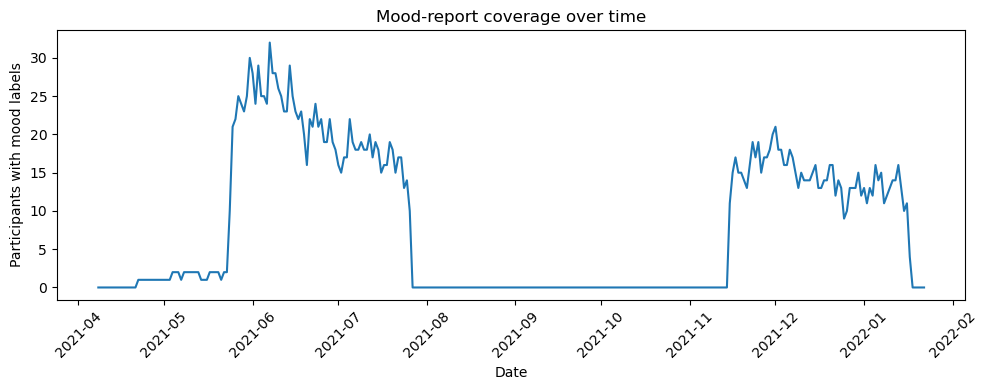

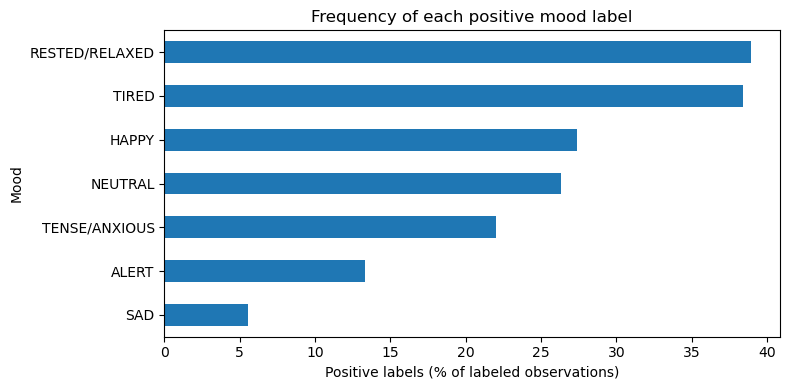

In [13]:



'''audit = df_sample.copy()
audit["date"] = pd.to_datetime(audit["date"], errors="coerce")
audit["has_mood_labels"] = audit[mood_list].notna().all(axis=1)'''

# Plot 1: labeled observations per participant
participant_counts = (
    audit.groupby("id")["has_mood_labels"]
    .sum()
)

plt.figure(figsize=(8, 4))
plt.hist(participant_counts, bins=15, edgecolor="black")
plt.xlabel("Number of days with recorded mood labels")
plt.ylabel("Number of participants")
plt.title("Mood-report coverage across participants")
plt.tight_layout()
plt.show()

# Plot 2: daily mood-report coverage
daily_counts = (
    audit.groupby("date")["has_mood_labels"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(10, 4))
plt.plot(daily_counts.index, daily_counts.values)
plt.xlabel("Date")
plt.ylabel("Participants with mood labels")
plt.title("Mood-report coverage over time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 3: positive mood-label frequency
labeled = audit.loc[audit["has_mood_labels"], mood_list]

positive_percent = 100 * labeled.eq(1).mean()
positive_percent = positive_percent.sort_values()

plt.figure(figsize=(8, 4))
positive_percent.plot(kind="barh")
plt.xlabel("Positive labels (% of labeled observations)")
plt.ylabel("Mood")
plt.title("Frequency of each positive mood label")
plt.tight_layout()

plt.savefig("figures/positive_mood_labels.png", dpi=300, bbox_inches="tight") 
plt.show()


1) Mood label per participants is varied from 0 to 80.
2) There seems to be 2 periods where mood is reported and a huge period inbetween where no mood is reported
3) Labels among reported moods vary with SAD being reported the least

## Check on 2 periods of mood report 

In [7]:


'''
audit = df_sample.copy()
audit["date"] = pd.to_datetime(audit["date"])

mood_list = [
    "ALERT", "HAPPY", "NEUTRAL", "RESTED/RELAXED",
    "SAD", "TENSE/ANXIOUS", "TIRED"
]

audit["has_mood_labels"] = audit[mood_list].notna().all(axis=1)'''

# Keep only days with recorded mood labels
labeled = audit[audit["has_mood_labels"]].copy()

# Define the two reporting periods
period1 = labeled[
    (labeled["date"] >= "2021-05-01") &
    (labeled["date"] < "2021-08-01")
]

period2 = labeled[
    (labeled["date"] >= "2021-11-01") &
    (labeled["date"] <= "2022-01-22")
]

participants1 = set(period1["id"])
participants2 = set(period2["id"])

print("Participants in first period:", len(participants1))
print("Participants in second period:", len(participants2))

print("Participants in both periods:",
      len(participants1 & participants2))

print("Only first period:",
      len(participants1 - participants2))

print("Only second period:",
      len(participants2 - participants1))

print("\nMood reports in first period:", len(period1))
print("Mood reports in second period:", len(period2))


Participants in first period: 36
Participants in second period: 28
Participants in both periods: 1
Only first period: 35
Only second period: 27

Mood reports in first period: 1362
Mood reports in second period: 920


The periods seems to be 2 different coherts with only 1 participant common among them

## Making next day mood_columns

In [8]:

mood_cols = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]

df = df_sample.copy()


df["date"] = pd.to_datetime(df["date"])

# Prepare tomorrow's mood labels
mood_next = df[["id", "date"] + mood_cols].copy()

# Shift tomorrow's mood 
mood_next["date"] = (
    mood_next["date"] - pd.Timedelta(days=1)    # nodate is missing from previous obsevation , so no worries here.
)

# Rename 
next_cols = [f"{m}_next" for m in mood_cols]

mood_next = mood_next.rename(
    columns=dict(zip(mood_cols, next_cols))
)

# Merge so that both today and tomorow columns present
df_next = df.merge(
    mood_next,
    on=["id", "date"],
    how="left",
    validate="one_to_one"
)


df_next = (
    df_next.dropna(subset=next_cols)
    .sort_values(["id", "date"])
    .reset_index(drop=True)
)

print("Usable next-day observations:", len(df_next))
print("Participants:", df_next["id"].nunique())

print("\nNext-day mood positive counts:")
print(df_next[next_cols].sum())


Usable next-day observations: 2276
Participants: 63

Next-day mood positive counts:
ALERT_next             304.0
HAPPY_next             623.0
NEUTRAL_next           602.0
RESTED/RELAXED_next    886.0
SAD_next               126.0
TENSE/ANXIOUS_next     502.0
TIRED_next             876.0
dtype: float64


## PLot of next day predictions available from participants

USABLE OBSERVATIONS PER PARTICIPANT
count    63.000000
mean     36.126984
std      23.852701
min       1.000000
25%      14.000000
50%      40.000000
75%      60.500000
max      83.000000
Name: n_observations, dtype: float64

Participants with fewer than 5 observations:
7

Participants with at least 10 observations:
49


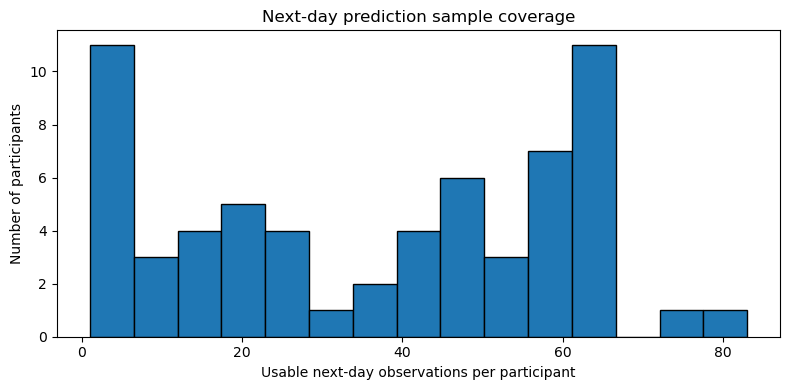

In [9]:

# Number of usable next-day observations per participant
participant_next_counts = (
    df_next.groupby("id")
    .size()
    .rename("n_observations")
)

print("USABLE OBSERVATIONS PER PARTICIPANT")
print(participant_next_counts.describe())

print("\nParticipants with fewer than 5 observations:")
print((participant_next_counts < 5).sum())



print("\nParticipants with at least 10 observations:")
print((participant_next_counts >= 10).sum())


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.hist(
    participant_next_counts,
    bins=15,
    edgecolor="black"
)

plt.xlabel("Usable next-day observations per participant")
plt.ylabel("Number of participants")
plt.title("Next-day prediction sample coverage")
plt.tight_layout()
plt.show()



## Split into Train and Test set chronologically as we are interested in future mood prediction

In [10]:


# Sort by participant and date
df_next = (
    df_next
    .sort_values(["id", "date"])
    .reset_index(drop=True)
)

train_indices = []
test_indices = []

min_samples = 10  # if number of samples less than  this , we use it for training only
test_fraction = 0.20

for participant_id, group in df_next.groupby("id"):

    n = len(group)

    if n < min_samples:
    
        train_indices.extend(group.index.tolist())

    else:
        # Reserve 20% for testing
        n_test = max(2, int(np.ceil(n * test_fraction)))
        split_point = n - n_test

        train_indices.extend(
            group.index[:split_point].tolist()
        )

        test_indices.extend(
            group.index[split_point:].tolist()
        )

df_train = df_next.loc[train_indices].copy()
df_test = df_next.loc[test_indices].copy()

print("Training observations:", len(df_train))
print("Testing observations:", len(df_test))

print("\nTraining participants:", df_train["id"].nunique())
print("Testing participants:", df_test["id"].nunique())

print("\nParticipants in both sets:",
      len(set(df_train["id"]) & set(df_test["id"])))


df_train.to_csv("data/train.csv", index=False)
df_test.to_csv("data/test.csv", index=False)


Training observations: 1815
Testing observations: 461

Training participants: 63
Testing participants: 49

Participants in both sets: 49


With this split , for a particular personal id, train set contains dates such that they precede the ones in the test set. we do this because we need future mood prediction.

## Check whether split did its job

In [11]:

# Check that no row appears in both sets
overlap = set(df_train.index) & set(df_test.index)

print("Overlapping row indices:", len(overlap))

# Check chronological ordering for each test participant
violations = []

for participant_id, test_group in df_test.groupby("id"):

    train_group = df_train[
        df_train["id"] == participant_id
    ]

    if train_group["date"].max() >= test_group["date"].min():
        violations.append(participant_id)

print("Participants violating chronological order:",
      violations)

# Check whether all observations are accounted for
print("Total after splitting:",
      len(df_train) + len(df_test))

print("Original total:", len(df_next))

# Check positive labels in both sets
next_cols = [
    "ALERT_next",
    "HAPPY_next",
    "NEUTRAL_next",
    "RESTED/RELAXED_next",
    "SAD_next",
    "TENSE/ANXIOUS_next",
    "TIRED_next"
]

print("TRAINING LABEL PREVALENCE (%)")
print((100 * df_train[next_cols].mean()).round(2))

print("TESTING LABEL PREVALENCE (%)")
print((100 * df_test[next_cols].mean()).round(2))

print("TESTING POSITIVE COUNTS")
print(df_test[next_cols].sum())


Overlapping row indices: 0
Participants violating chronological order: []
Total after splitting: 2276
Original total: 2276
TRAINING LABEL PREVALENCE (%)
ALERT_next             13.83
HAPPY_next             29.92
NEUTRAL_next           25.51
RESTED/RELAXED_next    40.06
SAD_next                5.95
TENSE/ANXIOUS_next     22.87
TIRED_next             39.17
dtype: float64
TESTING LABEL PREVALENCE (%)
ALERT_next             11.50
HAPPY_next             17.35
NEUTRAL_next           30.15
RESTED/RELAXED_next    34.49
SAD_next                3.90
TENSE/ANXIOUS_next     18.87
TIRED_next             35.79
dtype: float64
TESTING POSITIVE COUNTS
ALERT_next              53.0
HAPPY_next              80.0
NEUTRAL_next           139.0
RESTED/RELAXED_next    159.0
SAD_next                18.0
TENSE/ANXIOUS_next      87.0
TIRED_next             165.0
dtype: float64


The split was successfull, Onto EDA